In [15]:
import sys
import os
import json
import numpy as np
import scipy as sp


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [16]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [17]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'robot-2026-zimmermann'

In [18]:
file_ids = list(range(0, 33+1))
# file_ids = [19]

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
filenames = [read_utils.get_filename(read_utils.get_file_handle(path, file_id)).replace('worm', 'wyrm') for file_id in file_ids]

In [19]:
manual = True

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

# scores

In [20]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [21]:
boms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)[0] for filename in filenames]
hgms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)[0] for filename in filenames]

In [22]:
neuron_scores = assemble(boms_spn, hgms_spn)

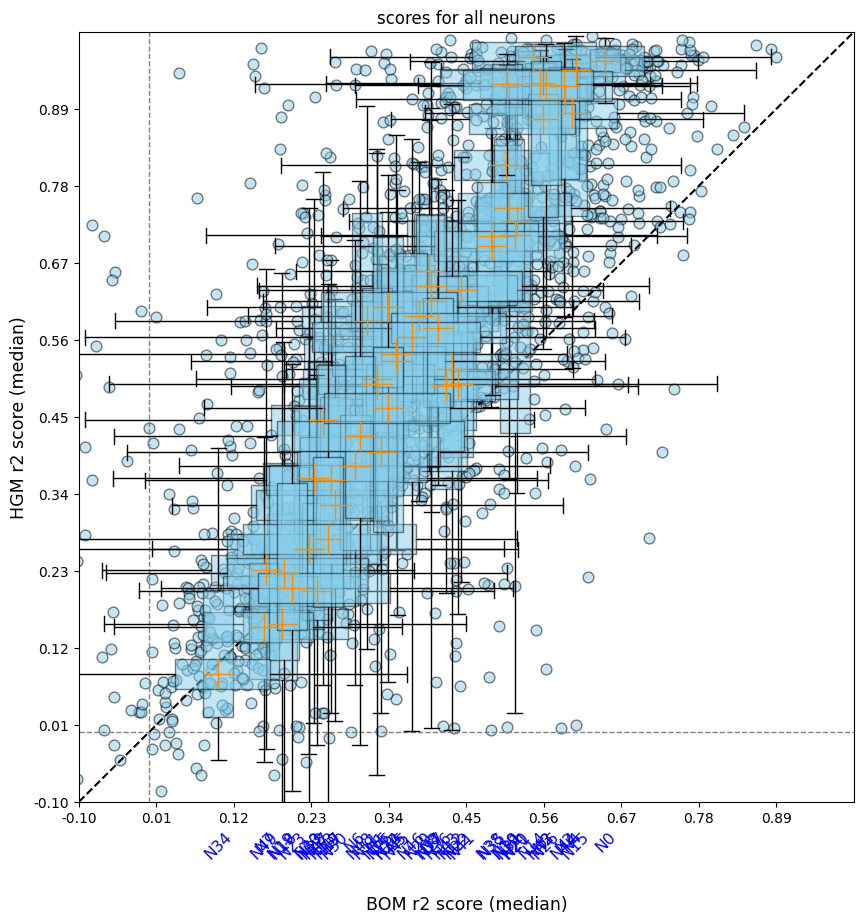

In [23]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=(-0.1, 1, -0.1, 1), force_medians=False
)

In [24]:
neuron_scores_hgm_rel = list(reversed(sorted({key: value for key, value in neuron_scores.items() if 0 < np.median(value[0]) < np.median(value[1])}.items(), key=lambda x: np.median(x[1][1]))))
neuron_scores_hgm_rel_labels = list([val[0] for val in neuron_scores_hgm_rel])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_hgm_rel]))

NEURON: N14,		HGMSCR: 0.9643
NEURON: N0,		HGMSCR: 0.9581
NEURON: N15,		HGMSCR: 0.9453
NEURON: N42,		HGMSCR: 0.9264
NEURON: N39,		HGMSCR: 0.9254
NEURON: N26,		HGMSCR: 0.9238
NEURON: N44,		HGMSCR: 0.9229
NEURON: N2,		HGMSCR: 0.9036
NEURON: N4,		HGMSCR: 0.8845
NEURON: N3,		HGMSCR: 0.8749
NEURON: N10,		HGMSCR: 0.8093
NEURON: N31,		HGMSCR: 0.7481
NEURON: N21,		HGMSCR: 0.7297
NEURON: N20,		HGMSCR: 0.7097
NEURON: N38,		HGMSCR: 0.7089
NEURON: N35,		HGMSCR: 0.6941
NEURON: N37,		HGMSCR: 0.6577
NEURON: N8,		HGMSCR: 0.6374
NEURON: N41,		HGMSCR: 0.6307
NEURON: N27,		HGMSCR: 0.6155
NEURON: N24,		HGMSCR: 0.6063
NEURON: N29,		HGMSCR: 0.5941
NEURON: N11,		HGMSCR: 0.5869
NEURON: N36,		HGMSCR: 0.5768
NEURON: N46,		HGMSCR: 0.5637
NEURON: N45,		HGMSCR: 0.5404
NEURON: N5,		HGMSCR: 0.5295
NEURON: N12,		HGMSCR: 0.5178
NEURON: N16,		HGMSCR: 0.5045
NEURON: N1,		HGMSCR: 0.4969
NEURON: N22,		HGMSCR: 0.4969
NEURON: N43,		HGMSCR: 0.4935
NEURON: N32,		HGMSCR: 0.4633
NEURON: N13,		HGMSCR: 0.4456
NEURON: N48,		HGMSCR:

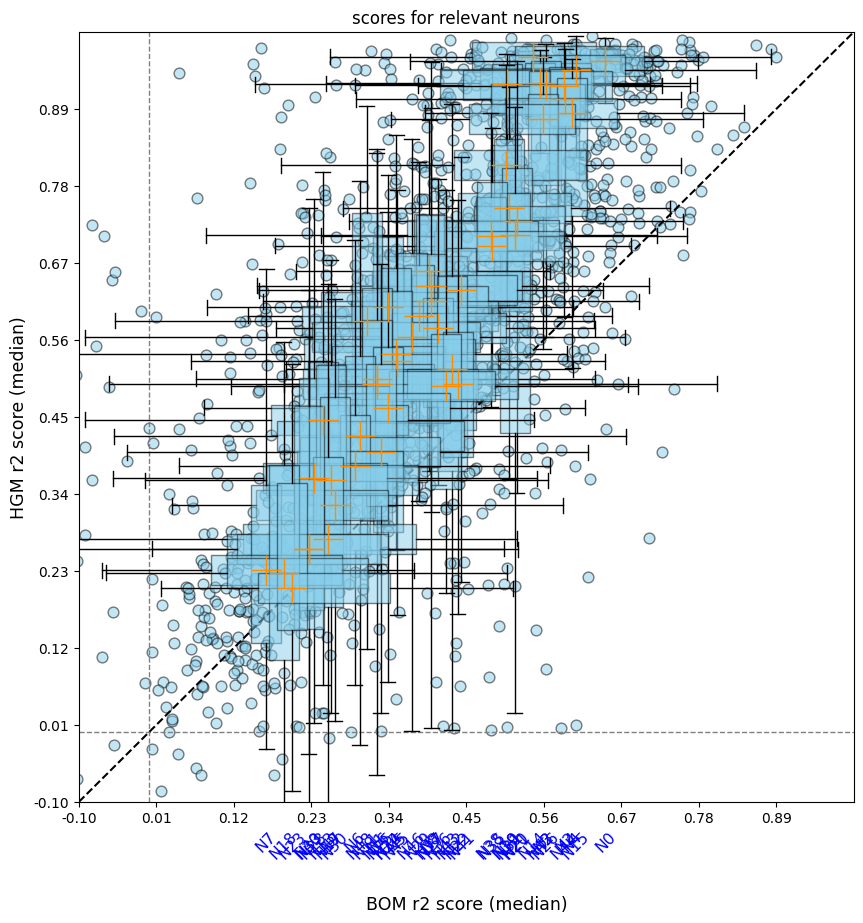

In [25]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_rel_labels}, None,
	title='scores for relevant neurons', limits=(-0.1, 1, -0.1, 1), force_medians=False
)

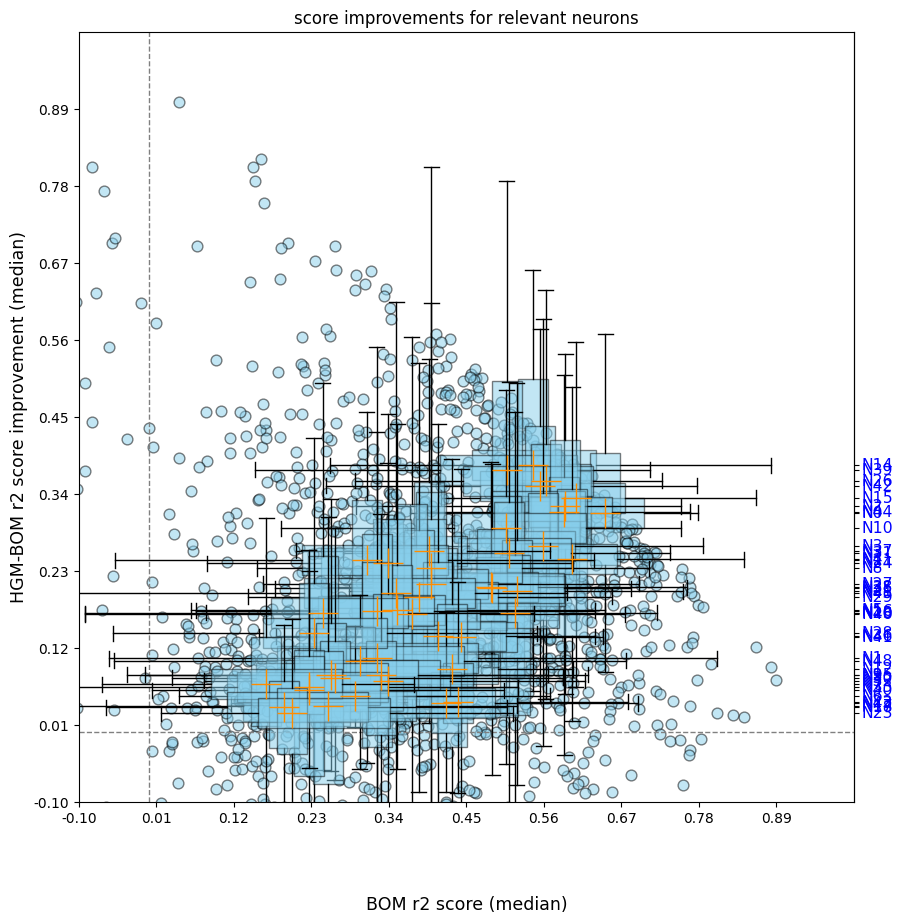

In [26]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_rel_labels}, None,
	title='score improvements for relevant neurons', limits=(-0.1, 1, -0.1, 1), force_medians=False
)

In [27]:
neuron_impros_hgm_rel = list(reversed(sorted(neuron_scores_hgm_rel, key=lambda x: np.median(x[1][1] - x[1][0]))))
neuron_impros_hgm_rel_labels = list([val[0] for val in neuron_impros_hgm_rel])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_hgm_rel]))

NEURON: N14,		IMPR: 0.3806
NEURON: N39,		IMPR: 0.3747
NEURON: N26,		IMPR: 0.3585
NEURON: N42,		IMPR: 0.3513
NEURON: N15,		IMPR: 0.3341
NEURON: N2,		IMPR: 0.3219
NEURON: N44,		IMPR: 0.3146
NEURON: N0,		IMPR: 0.3129
NEURON: N10,		IMPR: 0.2908
NEURON: N3,		IMPR: 0.2660
NEURON: N37,		IMPR: 0.2587
NEURON: N31,		IMPR: 0.2555
NEURON: N4,		IMPR: 0.2465
NEURON: N11,		IMPR: 0.2453
NEURON: N24,		IMPR: 0.2405
NEURON: N8,		IMPR: 0.2336
NEURON: N27,		IMPR: 0.2117
NEURON: N38,		IMPR: 0.2063
NEURON: N35,		IMPR: 0.2052
NEURON: N21,		IMPR: 0.2011
NEURON: N45,		IMPR: 0.1986
NEURON: N29,		IMPR: 0.1931
NEURON: N5,		IMPR: 0.1735
NEURON: N16,		IMPR: 0.1731
NEURON: N20,		IMPR: 0.1701
NEURON: N13,		IMPR: 0.1694
NEURON: N46,		IMPR: 0.1680
NEURON: N28,		IMPR: 0.1411
NEURON: N36,		IMPR: 0.1365
NEURON: N41,		IMPR: 0.1356
NEURON: N1,		IMPR: 0.1051
NEURON: N48,		IMPR: 0.1018
NEURON: N12,		IMPR: 0.0895
NEURON: N9,		IMPR: 0.0816
NEURON: N25,		IMPR: 0.0815
NEURON: N30,		IMPR: 0.0772
NEURON: N32,		IMPR: 0.0731
NEURON: N

In [28]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_hgm_rel_labels]))

Neuron names for copying:
'N14', 'N39', 'N26', 'N42', 'N15', 'N2', 'N44', 'N0', 'N10', 'N3', 'N37', 'N31', 'N4', 'N11', 'N24', 'N8', 'N27', 'N38', 'N35', 'N21', 'N45', 'N29', 'N5', 'N16', 'N20', 'N13', 'N46', 'N28', 'N36', 'N41', 'N1', 'N48', 'N12', 'N9', 'N25', 'N30', 'N32', 'N7', 'N33', 'N40', 'N6', 'N22', 'N43', 'N17', 'N18', 'N23'
